# Compare RFMODE=0 and RFMODE=1 for NMOS

**Copyright 2026 Michael Koefinger**

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
You may obtain a copy of the License at
http://www.apache.org/licenses/LICENSE-2.0

In [1]:
# read table data
import matplotlib.pyplot as plt
from pygmid import Lookup as lk
import numpy as np
lv_nmos_rfmode0 = lk('sg13_lv_nmosrfmode0.mat')
lv_nmos_rfmode1 = lk('sg13_lv_nmosrfmode1.mat')
# list of parameters: VGS, VDS, VSB, L, W, NFING, ID, VT, GM, GMB, GDS, CGG, CGB, CGD, CGS, CDD, CSS, STH, SFL
# if not specified, minimum L, VDS=max(vgs)/2=0.9 and VSB=0 are used 

In [2]:
# Define VDS, L, and gm/ID values
vds_vec = np.array([150e-3, 300e-3, 450e-3, 600e-3, 750e-3, 900e-3, 1.05, 1.2, 1.35])
L = 0.13
gm_id_vec = np.arange(1, 28, 0.5)
vgs_vec = np.zeros((len(gm_id_vec), len(vds_vec)))
fT_vec = np.zeros((len(gm_id_vec), len(vds_vec)))

In [3]:
# Lookup VGS and fT for each gm/ID and VDS combination for rfmode=0
for i in range(len(gm_id_vec)):
    for j in range(len(vds_vec)):
        vgs_vec[i, j] = lv_nmos_rfmode0.look_upVGS(GM_ID=gm_id_vec[i], VDS=vds_vec[j], L=L)
        fT_vec[i, j] = lv_nmos_rfmode0.lookup('GM_CGG', GM_ID=gm_id_vec[i], VDS=vds_vec[j], L=L)/2/np.pi

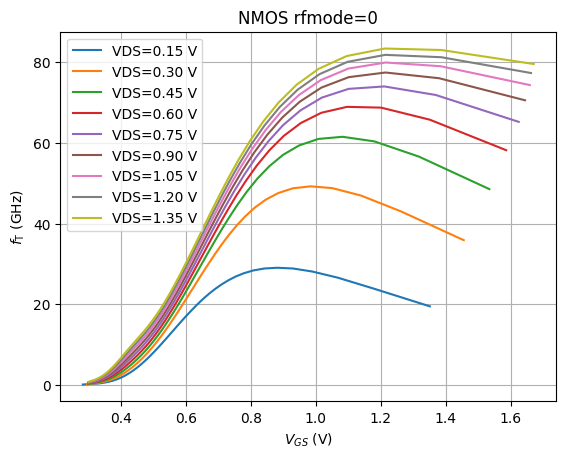

In [4]:
# Plot fT vs VGS for each VDS
fig, ax = plt.subplots()
plt.title('NMOS rfmode=0')
for j in range(len(vds_vec)):
    ax.plot(vgs_vec[:,j], fT_vec[:,j]/1e9, label=f'VDS={vds_vec[j]:.2f} V')
plt.xlabel(r'$V_{GS}$ (V)')
plt.ylabel(r'$f_\mathrm{T}$ (GHz)')
plt.grid()
plt.legend()
plt.show()

In [5]:
# Lookup VGS and fT for each gm/ID and VDS combination for rfmode=1
for i in range(len(gm_id_vec)):
    for j in range(len(vds_vec)):
        vgs_vec[i, j] = lv_nmos_rfmode1.look_upVGS(GM_ID=gm_id_vec[i], VDS=vds_vec[j], L=L)
        fT_vec[i, j] = lv_nmos_rfmode1.lookup('GM_CGG', GM_ID=gm_id_vec[i], VDS=vds_vec[j], L=L)/2/np.pi

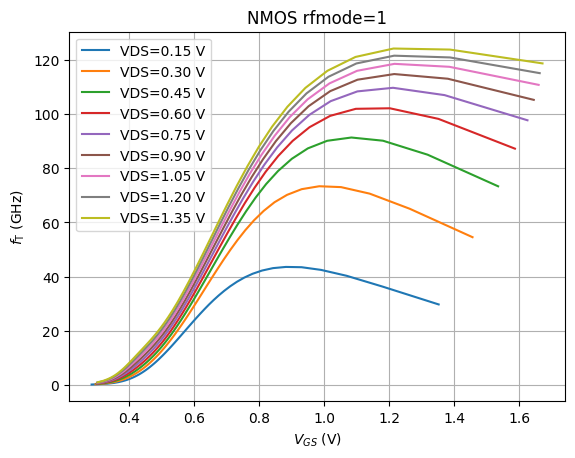

In [6]:
# Plot fT vs VGS for each VDS
fig, ax = plt.subplots()
plt.title('NMOS rfmode=1')
for j in range(len(vds_vec)):
    ax.plot(vgs_vec[:,j], fT_vec[:,j]/1e9, label=f'VDS={vds_vec[j]:.2f} V')
plt.xlabel(r'$V_{GS}$ (V)')
plt.ylabel(r'$f_\mathrm{T}$ (GHz)')
plt.grid()
plt.legend()
plt.show()